# 12. Qualidade da medição: quando o modelo recebe valores errados

**Pergunta:** se os dados de entrada forem medidos, codificados ou transmitidos de maneira diferente, como variam as distribuições, os scores e o desempenho do modelo congelado? Este teste é complementar ao drift de composição da população. O modelo `model_class` foi refeito com `scale_pos_weight=13.882494684620836` e é usado com limiar **0,50**; todas as árvores armazenadas entram na inferência. As suítes anteriores permanecem preservadas.

**Interpretação causal indispensável.** O rótulo histórico do holdout permanece fixo porque os cenários representam **erros de medição ou de pipeline**: o mutuário não mudou, só o valor que chega ao modelo. Se a renda verdadeira caísse por crise econômica, manter o desfecho fixo não permitiria prever a inadimplência futura. Nenhum rótulo aleatório é criado.

Cada cenário começa de novo do **mesmo** holdout. Portanto, não acumulamos vários erros sem declarar. O `cs-test.csv` sem rótulos não mede AUC ROC, PR-AUC, KS do modelo nem Brier; aqui usamos os 22.500 exemplos rotulados separados do treino pelo split original.

## Roteiro

1. Conferir artefato, split e referência.
2. Definir as métricas e bins **antes** dos cenários.
3. Introduzir falhas controladas em etapas, sem reajustar o modelo.
4. Medir drift de entrada e de score, AUC ROC, PR-AUC trapezoidal, KS do modelo e Brier; consultar recall e precisão em 0,50 como referências.
5. Traçar curvas completas de sensibilidade, inclusive pontos de melhora, sem critério automático de parada.
6. Interpretar mecanismos e limitações para monitoramento.


In [1]:
from pathlib import Path

# Resolve o projeto tanto pelo Jupyter aberto em notebooks/ quanto pelo executor.
_inicio = Path.cwd().resolve()
PROJECT_ROOT = next(
    (p for p in (_inicio, *_inicio.parents)
     if (p / "models" / "manifesto_modelo.json").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Não encontrei models/manifesto_modelo.json. Abra o projeto clonado.")
DATA_DIR_PROJECT = PROJECT_ROOT / "data" / "raw"
MODEL_DIR = PROJECT_ROOT / "models"
TABLES_DIR = PROJECT_ROOT / "results" / "tables"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
for _nome in ("cs-training.csv", "cs-test.csv"):
    if not (DATA_DIR_PROJECT / _nome).is_file():
        raise FileNotFoundError(
            f"Falta {DATA_DIR_PROJECT / _nome}. Veja README.md, seção Dados."
        )


## 12.1 Modelo, dados e separação das amostras

`scale_pos_weight` é um peso de treinamento para erros da classe positiva; **não** é o limiar de decisão e **não** pode ser alterado apenas na inferência. O manifesto contém o hash SHA-256 do Booster para impedir mistura entre versões. `Xh` nunca participou do ajuste das árvores; `Xt` e `Xv` reconstruem o split original, sem estratificação. Valores ausentes reais não são imputados antes do XGBoost. A ordem das dez variáveis é verificada.


In [2]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             precision_recall_curve, roc_curve, auc)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
SEMENTE = 33
CORTE = 0.50
PESO_POSITIVO = 13.882494684620836
P = DATA_DIR_PROJECT
RAIZ = next((d for d in [P, P.parent] if (d / "cs-training.csv").is_file()), None)
if RAIZ is None:
    raise FileNotFoundError("Execute a partir da raiz do projeto ou de notebooks/.")
SAIDA = TABLES_DIR
SAIDA.mkdir(exist_ok=True)
MANIFESTO = json.loads((MODEL_DIR / 'manifesto_modelo.json').read_text(encoding="utf-8"))
ARQUIVO_MODELO = MODEL_DIR / 'model_class_retreinado.json'
assert abs(MANIFESTO["params_fornecidos"]["scale_pos_weight"] - PESO_POSITIVO) < 1e-12
assert MANIFESTO["cutoff"] == CORTE
assert hashlib.sha256(ARQUIVO_MODELO.read_bytes()).hexdigest() == MANIFESTO["model_sha256"]
FEATURES = MANIFESTO["features"]
ALVO = MANIFESTO["target"]
bruto = pd.read_csv(RAIZ / "cs-training.csv").drop(columns="Unnamed: 0")
assert list(bruto.drop(columns=ALVO).columns) == FEATURES
Xtv, Xh, ytv, yh = train_test_split(bruto[FEATURES], bruto[ALVO].astype(int),
                                    test_size=0.15, random_state=SEMENTE)
Xt, Xv, yt, yv = train_test_split(Xtv, ytv, test_size=0.1765, random_state=SEMENTE)
assert (len(Xt), len(Xv), len(Xh)) == (104996, 22504, 22500)
y = yh.to_numpy(dtype=int)
modelo = xgb.Booster()
modelo.load_model(str(ARQUIVO_MODELO))
assert modelo.feature_names is None or modelo.feature_names == FEATURES
modelo.set_param({"device": "cpu", "nthread": 4})  # Só a inferência vai para CPU.
assert modelo.num_boosted_rounds() == MANIFESTO["num_boosted_rounds"]
def predizer(X):
    return modelo.predict(xgb.DMatrix(X[FEATURES], feature_names=FEATURES)).astype(float)
p0 = predizer(Xh)
print("Treino:", len(Xt), "| validação:", len(Xv), "| holdout:", len(Xh))
print("Peso positivo:", PESO_POSITIVO, "| corte:", CORTE,
      "| árvores armazenadas:", modelo.num_boosted_rounds())

Treino: 104996 | validação: 22504 | holdout: 22500
Peso positivo: 13.882494684620836 | corte: 0.5 | árvores armazenadas: 103


## 12.2 Definições, fórmulas e legendas

* **ROC AUC**: probabilidade de um positivo ter score maior que um negativo em uma amostra comparável. Não usa o corte 0,50.
* **PR-AUC trapezoidal**: área sob a curva precisão–recall por integração trapezoidal, `auc(recall, precision)`. Maior é melhor; depende da prevalência. Usa todos os limiares de score.
* **AP (average precision)**: média ponderada da precisão nos aumentos de recall, `average_precision_score`. É complemento; **não equivale** à PR-AUC trapezoidal e não é a precisão no corte.
* **KS do modelo**: `max_t [TPR(t) − FPR(t)]` sobre os limiares da curva ROC. `TPR` é sensibilidade e `FPR` a taxa de falso positivo no limiar `t`. Este KS usa **rótulos e scores**; não é o teste KS de drift entre entradas.
* **Brier**: média de `(y_i − p_i)²`; menor é melhor. Com peso de classe alto no treino, o score pode perder interpretação probabilística calibrada, então o Brier deve ser observado separadamente.
* **Recall** `TP/(TP+FN)`: proporção de inadimplentes corretamente sinalizados no corte 0,50.
* **Precisão** `TP/(TP+FP)`: proporção de sinalizados que são positivos no corte 0,50; fica indefinida (`NaN`) se não houver decisões positivas.
* **FPR** `FP/(FP+TN)`: proporção de não inadimplentes sinalizados como positivos no corte 0,50.
* **Flip de decisão**: fração de linhas cuja classe `1[p_i ≥ 0,50]` mudou em relação à referência. Pode haver muitos flips mesmo com AUC quase estável.
* **PSI**: para cada bin `b`, `PSI = Σ_b (q_b − r_b) ln(q_b/r_b)`, onde `r_b` é a fração na referência, `q_b` a fração no cenário, e `Σ_b` soma os bins. Bins são limites de quantis fixados no holdout sem estresse, mais um bin para ausentes. Um `ε=10⁻⁶` somente evita logaritmo de zero. PSI zero significa distribuições idênticas nesses bins; ele não é uma métrica de qualidade preditiva nem tem ponto de corte universal.

**Como as áreas são calculadas.** Para os pontos `(R_j,P_j)` da curva precisão–recall em ordem crescente de recall, `PR-AUC_trap = Σ_j (R_{j+1}−R_j)(P_{j+1}+P_j)/2`. `R_j` é o recall e `P_j` a precisão no ponto `j`; a soma cobre os segmentos vizinhos. É uma interpolação por retas, que pode dar valor diferente da AP, calculada por degraus. `ROC AUC` é a área sob a curva TPR versus FPR; KS do modelo é a maior distância vertical `max_t(TPR(t)−FPR(t))`, com `t` percorrendo os limiares. Para `n` rótulos verdadeiros `y_i∈{0,1}` e scores `p_i∈[0,1]`, `Brier = (1/n)Σ_i(y_i−p_i)²`. `n` é o número de registros e `i` seu índice. Essas quatro métricas requerem rótulos; PSI e flips de score podem ser vistos sem rótulo. Todas usam o mesmo holdout nos cenários de medição.

Nos gráficos, **entrada PSI** é o PSI da coluna alterada; **score PSI** compara as saídas do modelo. A intensidade nominal pode ser diferente da fração efetiva de linhas mudadas; ambas são exibidas. Como os bins são discretos, **PSI próximo de zero não significa que nenhuma linha mudou**: uma alteração dentro do mesmo bin pode ser invisível a ele; consulte `mudou_entrada` e `flip_050` em conjunto. Todo delta é `métrica_cenário − métrica_base`, em pontos da escala 0–1. Para AUC ROC, PR-AUC e KS, delta negativo indica queda; para Brier, delta positivo indica erro quadrático maior. Não há limiar de parada: cada ponto é interpretado pela magnitude, direção e plausibilidade do mecanismo.

**Fontes das definições:** [curva precisão–recall](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_recall_curve.html), [área trapezoidal](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.auc.html), [AP](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html), [curva ROC](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_curve.html) e [Brier](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.brier_score_loss.html), documentação oficial do scikit-learn.


In [3]:
def metricas(y, p, pesos=None):
    y = np.asarray(y, dtype=int)
    p = np.asarray(p, dtype=float)
    w = np.ones(len(y), dtype=float) if pesos is None else np.asarray(pesos, dtype=float)
    if not (len(y) == len(p) == len(w)) or not np.isfinite(w).all() or (w < 0).any() or w.sum() <= 0:
        raise ValueError("Rótulos, escores ou pesos inválidos.")
    classe = p >= CORTE
    tp = w[(y == 1) & classe].sum()
    fn = w[(y == 1) & ~classe].sum()
    fp = w[(y == 0) & classe].sum()
    tn = w[(y == 0) & ~classe].sum()
    prev = np.average(y, weights=w)
    if np.unique(y[w > 0]).size < 2:
        raise ValueError("AUC ROC, PR-AUC e KS exigem as duas classes com peso positivo.")
    precision_curve, recall_curve, _ = precision_recall_curve(y, p, sample_weight=w)
    fpr_curve, tpr_curve, _ = roc_curve(y, p, sample_weight=w, drop_intermediate=False)
    ap = average_precision_score(y, p, sample_weight=w)
    return {
        "auc_roc": roc_auc_score(y, p, sample_weight=w),
        "pr_auc_trap": auc(recall_curve, precision_curve),
        "ks_modelo": float(np.max(tpr_curve - fpr_curve)),
        "ap": ap,
        "ap_lift": ap / prev,
        "brier": brier_score_loss(y, p, sample_weight=w),
        "recall": tp / (tp + fn),
        "fpr": fp / (fp + tn),
        "precision": tp / (tp + fp) if tp + fp else np.nan,
        "prevalencia": prev,
        "score_medio": np.average(p, weights=w),
        "taxa_alerta": np.average(classe, weights=w),
        "ess": w.sum() ** 2 / np.square(w).sum(),
        "ess_frac": w.sum() ** 2 / np.square(w).sum() / len(w),
    }

def bins_referencia(ref, n_quant=10):
    a = np.asarray(ref, dtype=float)
    a = a[np.isfinite(a)]
    if len(a) == 0:
        return np.array([-np.inf, np.inf])
    internos = np.unique(np.quantile(a, np.linspace(0, 1, n_quant + 1)[1:-1]))
    return np.r_[-np.inf, internos, np.inf]

def contagens(x, arestas, pesos=None):
    a = np.asarray(x, dtype=float)
    w = np.ones(len(a)) if pesos is None else np.asarray(pesos, dtype=float)
    faltante = ~np.isfinite(a)
    cod = np.searchsorted(arestas, a[~faltante], side="right") - 1
    cod = np.clip(cod, 0, len(arestas) - 2)
    bins = np.bincount(cod, weights=w[~faltante], minlength=len(arestas)-1)
    return np.r_[bins, w[faltante].sum()]

def psi(ref, atual, arestas=None, pesos=None, epsilon=1e-6):
    """PSI descritivo, com bins fixos e bin separado para ausência/infinitos."""
    if arestas is None:
        arestas = bins_referencia(ref)
    r = contagens(ref, arestas)
    q = contagens(atual, arestas, pesos)
    r = r / r.sum()
    q = q / q.sum()
    return float(np.sum((q-r) * np.log((q+epsilon)/(r+epsilon))))

base = metricas(y, p0)
for chave, chave_manifesto in [("auc_roc", "auc_roc"), ("pr_auc_trap", "pr_auc_trap"),
                              ("ks_modelo", "ks_modelo"), ("ap", "ap"), ("brier", "brier")]:
    assert np.isclose(base[chave], MANIFESTO["baseline_holdout"][chave_manifesto], atol=1e-6, rtol=0), chave
display(pd.DataFrame([base], index=["Holdout sem estresse"]).round(4))

,auc_roc,pr_auc_trap,ks_modelo,ap,ap_lift,brier,recall,fpr,precision,prevalencia,score_medio,taxa_alerta,ess,ess_frac
Holdout sem estresse,0.8668,0.396,0.5877,0.3964,5.9458,0.144,0.794,0.2068,0.2153,0.0667,0.324,0.2459,22500.0,1.0


## 12.3 Desenho dos estressores

O parâmetro `nível` representa:

| Família | Implementação | Níveis | Leitura correta |
|---|---|---|---|
| Renda ausente em baixa renda | Substituir por `NaN` os menores valores de renda observados. | 5%, 10%, 20%, 40% dos registros originalmente observados | Perda informativa de informação; seleção usa somente `X`. |
| Ruído de renda | Multiplicar renda por `exp(σ z − σ²/2)`, com `z` normal fixo por linha. | σ = 0,05; 0,10; 0,20; 0,40 | Erro aleatório multiplicativo; a correção `−σ²/2` preserva a média do fator em expectativa. |
| Erro de escala do DebtRatio | Multiplicar a razão por `1−δ` e `1+δ`, reiniciando da mesma base a cada cenário. | δ = 5%, 10%, …, 50% em cada direção | Erro sistemático de escala, sem alteração real do cliente. É a família de mudança percentual bilateral; as demais famílias usam unidades próprias. |
| Unidade errada de renda | Multiplicar por 100 uma fração crescente de registros selecionados com semente fixa. | 0,1%, 0,5%, 1%, 5% dos observados | Erro raro de unidade; valor extremo deliberado. |
| Teto de utilização | Truncar valores acima de quantis do **treino**. | 99,9%; 99%; 95%; 90% | Perda de cauda por cap de pipeline; o parâmetro exibido é a fração superior truncável. |
| Arredondamento de idade | Arredondar ao múltiplo mais próximo. | 5, 10, 20 anos | Coarsening cadastral; valor do nível está em anos. |

A renda da primeira família é ordenada da menor para a maior. Assim, os subconjuntos são aninhados e não usam `y`; isso facilita comparar níveis. O ruído e a unidade errada reutilizam o mesmo sorteio de linhas/erro em todos os níveis. O teto é definido a partir do treino, reduzindo vazamento na especificação do limite. Esses cenários são testes de sensibilidade: não são uma previsão da frequência dos erros em produção.


In [4]:
rng = np.random.default_rng(SEMENTE)
observada_renda = np.flatnonzero(Xh["MonthlyIncome"].notna().to_numpy())
ordem_renda_baixa = observada_renda[np.argsort(Xh.iloc[observada_renda]["MonthlyIncome"].to_numpy(), kind="stable")]
ordem_unidade = rng.permutation(observada_renda)
z_renda = rng.standard_normal(len(Xh))

cenarios = []
for frac in [0.05, 0.10, 0.20, 0.40]:
    X = Xh.copy()
    n = round(frac * len(observada_renda))
    X.iloc[ordem_renda_baixa[:n], X.columns.get_loc("MonthlyIncome")] = np.nan
    cenarios.append(("Ausência informativa de renda", frac, f"{frac:.0%} dos observados", "MonthlyIncome", X))

for sigma in [0.05, 0.10, 0.20, 0.40]:
    X = Xh.copy()
    renda = X["MonthlyIncome"].to_numpy(copy=True)
    mascara = np.isfinite(renda)
    renda[mascara] *= np.exp(sigma * z_renda[mascara] - sigma**2 / 2)
    X["MonthlyIncome"] = renda
    cenarios.append(("Ruído multiplicativo da renda", sigma, f"σ={sigma:.2f}", "MonthlyIncome", X))

for direcao, sinal in [("Subregistro do DebtRatio", -1), ("Sobre-registro do DebtRatio", 1)]:
    for delta in np.arange(5, 51, 5) / 100:
        X = Xh.copy()
        X["DebtRatio"] = X["DebtRatio"] * (1 + sinal * delta)
        cenarios.append((direcao, delta, f"{sinal * delta:+.0%}", "DebtRatio", X))

for frac in [0.001, 0.005, 0.01, 0.05]:
    X = Xh.copy()
    n = max(1, round(frac * len(observada_renda)))
    pos = ordem_unidade[:n]
    X.iloc[pos, X.columns.get_loc("MonthlyIncome")] *= 100.0
    cenarios.append(("Unidade da renda ×100", frac, f"{frac:.1%} dos observados", "MonthlyIncome", X))

for q in [0.999, 0.99, 0.95, 0.90]:
    X = Xh.copy()
    teto = float(Xt["RevolvingUtilizationOfUnsecuredLines"].quantile(q))
    X["RevolvingUtilizationOfUnsecuredLines"] = X["RevolvingUtilizationOfUnsecuredLines"].clip(upper=teto)
    cenarios.append(("Teto de utilização", 1-q, f"teto Q{q:.1%}={teto:.3g}",
                     "RevolvingUtilizationOfUnsecuredLines", X))

for passo in [5, 10, 20]:
    X = Xh.copy()
    X["age"] = (np.round(X["age"] / passo) * passo).clip(lower=0)
    cenarios.append(("Idade arredondada", passo, f"múltiplos de {passo} anos", "age", X))

print("Cenários:", len(cenarios), "| cada cenário reinicia do holdout original")
display(pd.DataFrame([(f, nivel, desc, var) for f, nivel, desc, var, _ in cenarios],
                     columns=["família", "nível", "descrição", "variável"]).head(12))

Cenários: 39 | cada cenário reinicia do holdout original


,família,nível,descrição,variável
0,Ausência informativa de renda,0.05,5% dos observados,MonthlyIncome
1,Ausência informativa de renda,0.10,10% dos observados,MonthlyIncome
2,Ausência informativa de renda,0.20,20% dos observados,MonthlyIncome
3,Ausência informativa de renda,0.40,40% dos observados,MonthlyIncome
4,Ruído multiplicativo da renda,0.05,σ=0.05,MonthlyIncome
5,Ruído multiplicativo da renda,0.10,σ=0.10,MonthlyIncome
6,Ruído multiplicativo da renda,0.20,σ=0.20,MonthlyIncome
7,Ruído multiplicativo da renda,0.40,σ=0.40,MonthlyIncome
8,Subregistro do DebtRatio,0.05,-5%,DebtRatio
9,Subregistro do DebtRatio,0.10,-10%,DebtRatio


## 12.4 Executar e quantificar

Para cada cenário calculamos `p_i^s` com o **mesmo** Booster, e comparamos com `p_i^0`. Por exemplo, `delta_pr_auc_trap = PR-AUC_s − PR-AUC_0`; valor negativo indica queda nessa área. O PSI de score é útil para monitorar mudanças mesmo quando ainda não há rótulos, mas sua relação com perda de desempenho não é determinística. `mudou_entrada` é a fração de linhas cuja variável alvo realmente mudou (incluindo novos ausentes). `flip_050` é a fração cuja decisão mudou no corte fixo. AP, recall, precisão e FPR são exibidos como contexto, sem interromper a simulação.


In [5]:
linhas = []
arestas_score = bins_referencia(p0)
for familia, nivel, descricao, var, Xs in cenarios:
    ps = predizer(Xs)
    m = metricas(y, ps)
    a = Xh[var].to_numpy(dtype=float)
    b = Xs[var].to_numpy(dtype=float)
    mesmo = (a == b) | (np.isnan(a) & np.isnan(b))
    linha = {
        "familia": familia, "nivel": nivel, "descricao": descricao, "variavel": var,
        "mudou_entrada": 1 - mesmo.mean(),
        "psi_entrada": psi(a, b),
        "psi_score": psi(p0, ps, arestas_score),
        "flip_050": np.mean((p0 >= CORTE) != (ps >= CORTE)),
        "delta_score_medio": ps.mean() - p0.mean(),
        "delta_ap": m["ap"] - base["ap"],
        "delta_auc_roc": m["auc_roc"] - base["auc_roc"],
        "delta_pr_auc_trap": m["pr_auc_trap"] - base["pr_auc_trap"],
        "delta_ks_modelo": m["ks_modelo"] - base["ks_modelo"],
        "delta_brier": m["brier"] - base["brier"],
        "delta_recall": m["recall"] - base["recall"],
        "delta_precision": m["precision"] - base["precision"],
        "delta_fpr": m["fpr"] - base["fpr"],
    }
    linha.update(m)
    linhas.append(linha)
resultado = pd.DataFrame(linhas)
assert len(resultado) == 39 and resultado["psi_entrada"].ge(0).all()
resultado.to_csv(SAIDA / "12_qualidade_medicao_cenarios.csv", index=False)
display(resultado[["familia", "descricao", "mudou_entrada", "psi_entrada", "psi_score",
                   "auc_roc", "pr_auc_trap", "ks_modelo", "brier", "ap", "recall", "precision", "fpr", "flip_050"]].round(4))

,familia,descricao,mudou_entrada,psi_entrada,psi_score,auc_roc,pr_auc_trap,ks_modelo,brier,ap,recall,precision,fpr,flip_050
0,Ausência informativa de renda,5% dos observados,0.0402,0.0373,0.0001,0.8667,0.3944,0.5880,0.1445,0.3948,0.7960,0.2142,0.2085,0.0028
1,Ausência informativa de renda,10% dos observados,0.0803,0.8905,0.0003,0.8667,0.3940,0.5871,0.1433,0.3943,0.7933,0.2151,0.2068,0.0046
2,Ausência informativa de renda,20% dos observados,0.1606,1.9100,0.0012,0.8660,0.3938,0.5840,0.1413,0.3942,0.7873,0.2165,0.2035,0.0080
3,Ausência informativa de renda,40% dos observados,0.3212,3.8701,0.0040,0.8655,0.3939,0.5832,0.1387,0.3943,0.7827,0.2187,0.1997,0.0132
4,Ruído multiplicativo da renda,σ=0.05,0.7912,0.0025,0.0000,0.8669,0.3962,0.5880,0.1440,0.3966,0.7933,0.2153,0.2065,0.0019
5,Ruído multiplicativo da renda,σ=0.10,0.7912,0.0027,0.0001,0.8669,0.3962,0.5884,0.1441,0.3966,0.7933,0.2152,0.2066,0.0033
6,Ruído multiplicativo da renda,σ=0.20,0.7912,0.0070,0.0001,0.8669,0.3971,0.5871,0.1443,0.3975,0.7927,0.2148,0.2070,0.0064
7,Ruído multiplicativo da renda,σ=0.40,0.7912,0.0393,0.0002,0.8668,0.3971,0.5871,0.1448,0.3975,0.7947,0.2133,0.2094,0.0120
8,Subregistro do DebtRatio,-5%,0.9704,0.0035,0.0001,0.8670,0.3957,0.5875,0.1427,0.3961,0.7893,0.2168,0.2037,0.0048
9,Subregistro do DebtRatio,-10%,0.9704,0.0146,0.0004,0.8668,0.3956,0.5859,0.1414,0.3960,0.7840,0.2186,0.2001,0.0088


## 12.5 Visualização e leitura

Cada linha do primeiro painel é uma família de erro; as colunas mostram PSI de entrada, PSI de score e as quatro métricas centrais. As unidades de `nível` diferem entre famílias; compare **dentro** da linha. O segundo gráfico relaciona PSI observado da entrada com variação da PR-AUC trapezoidal; a relação pode ser irregular porque PSI olha apenas a distribuição marginal e PR-AUC depende das classes e do ranking. `log1p(PSI)` apenas comprime o eixo, sem mudar o PSI calculado. Recall e precisão no corte ficam na tabela como referência descritiva.


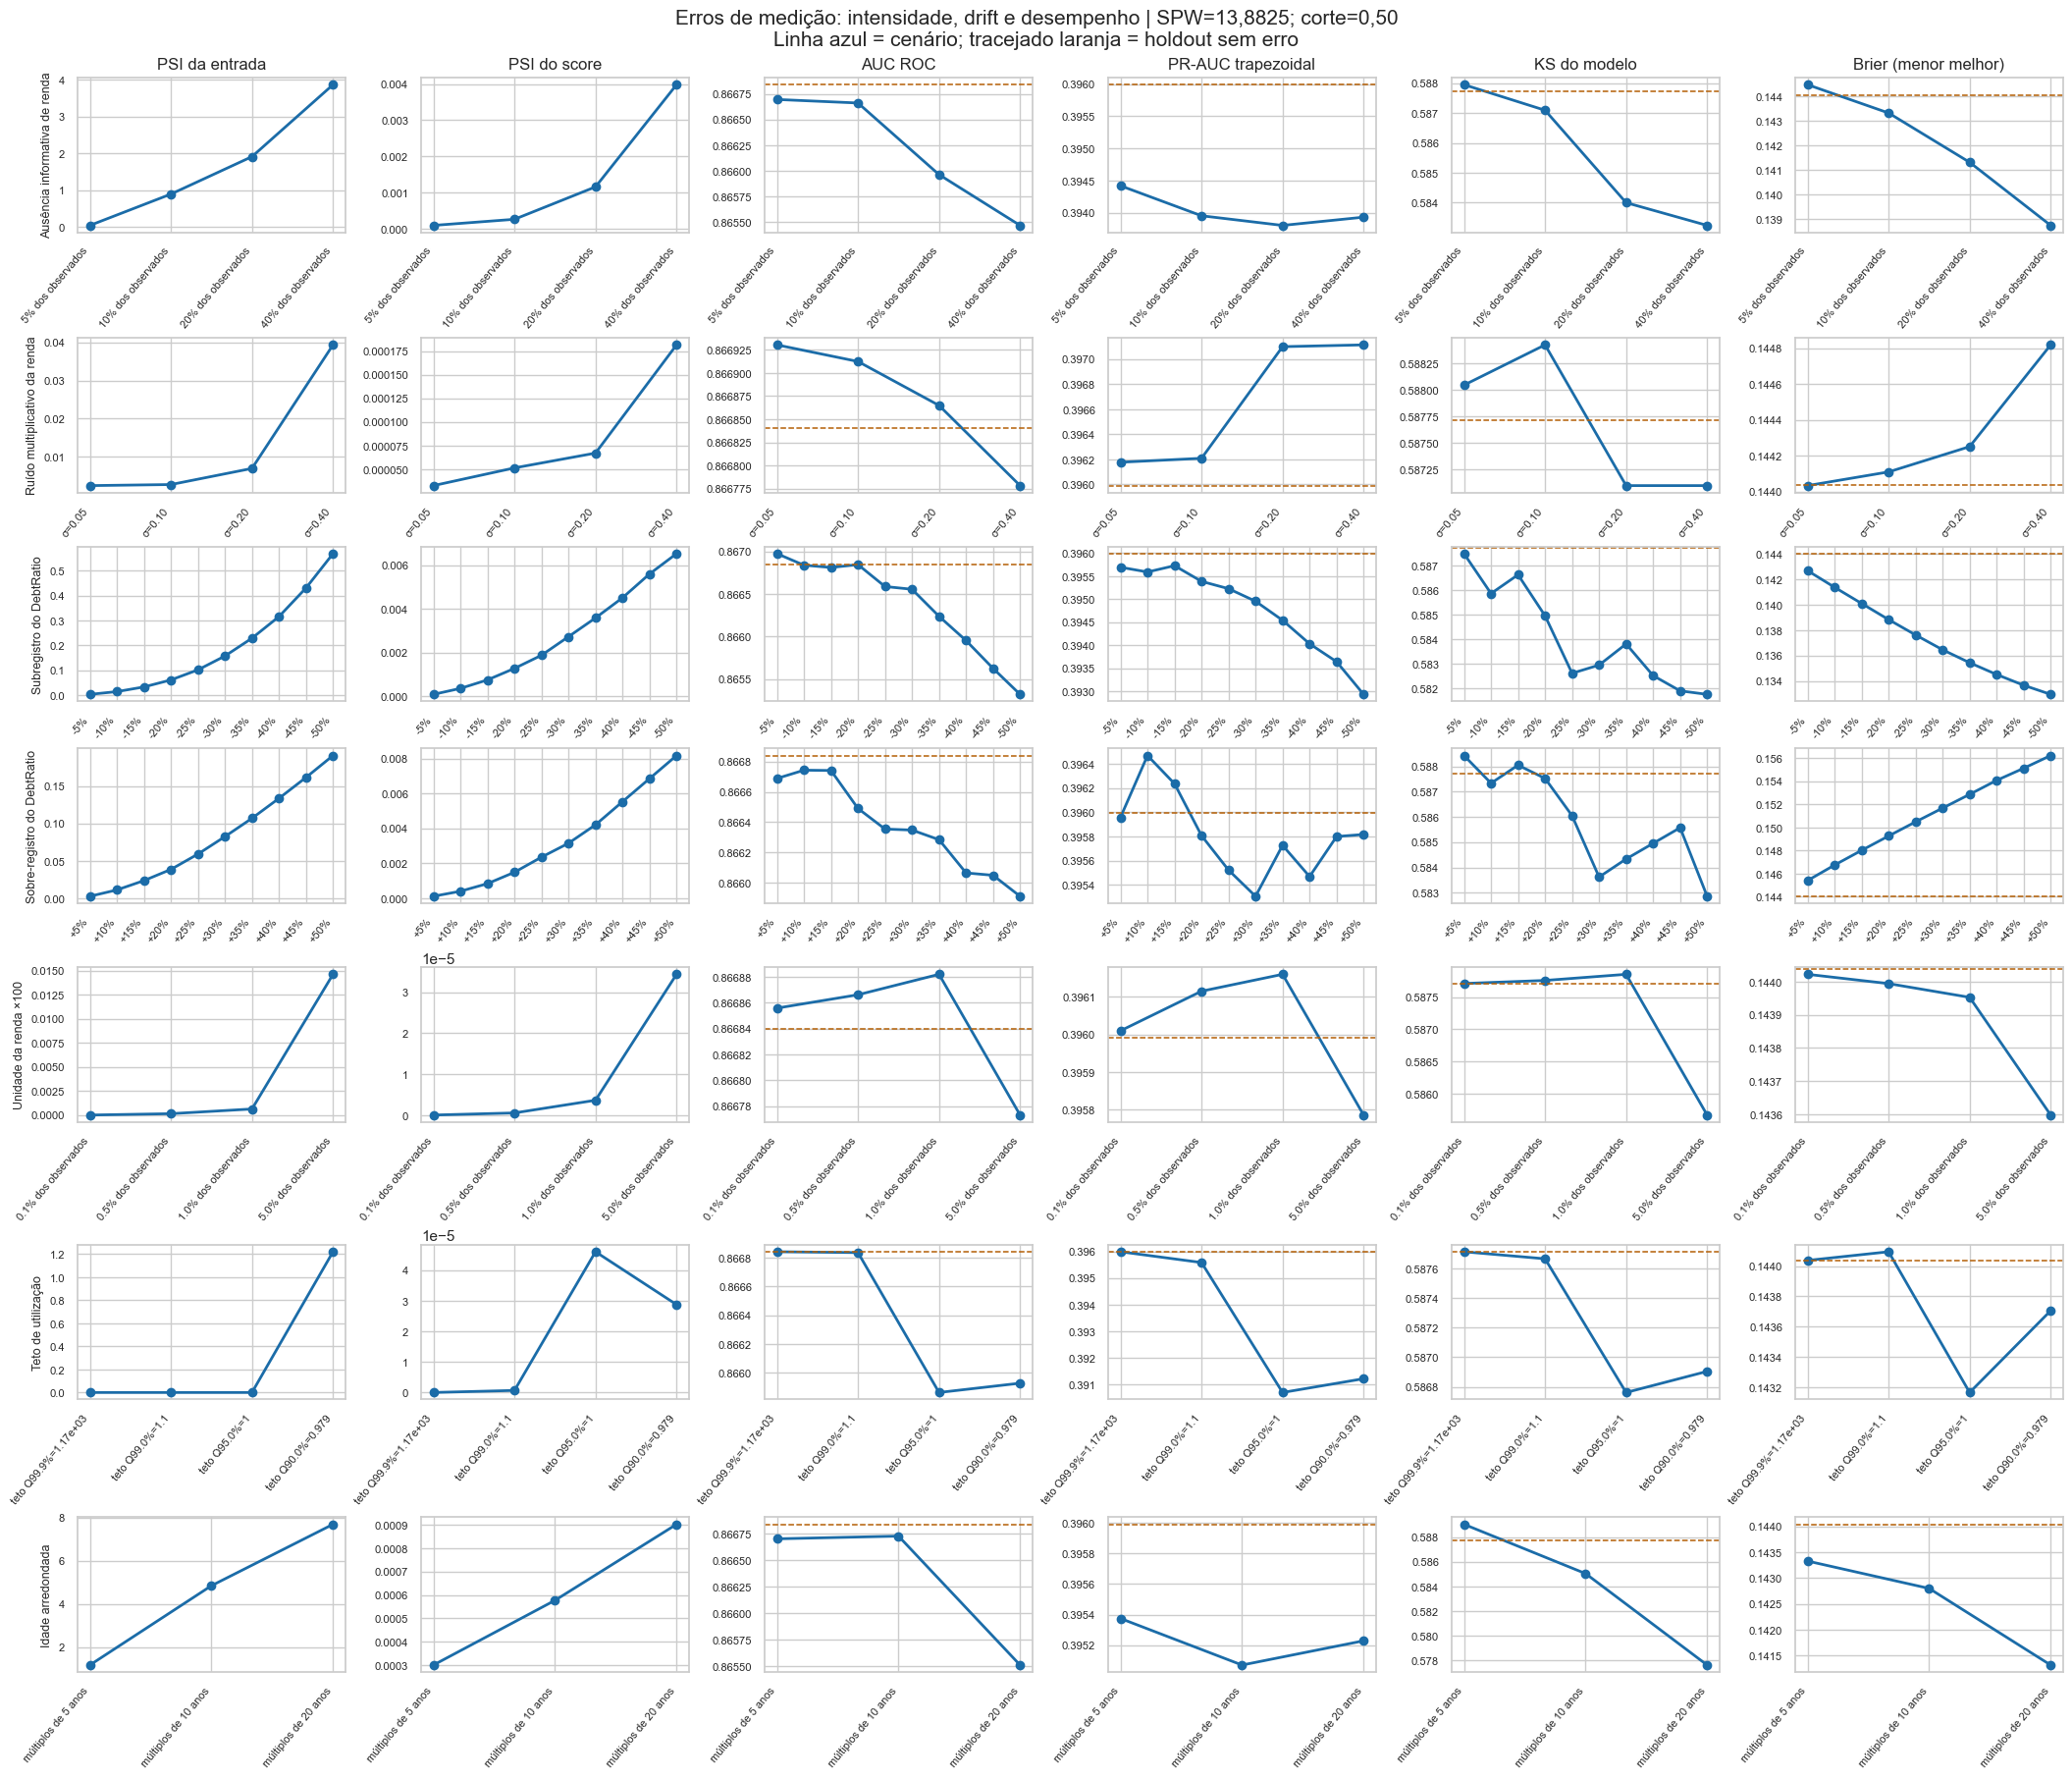

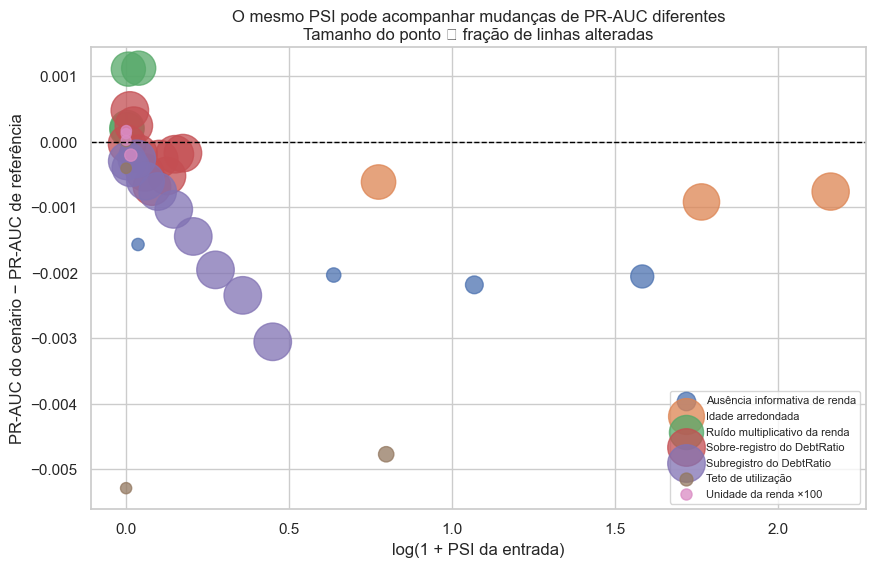

In [6]:
familias = resultado["familia"].drop_duplicates().tolist()
colunas = [("psi_entrada", "PSI da entrada"), ("psi_score", "PSI do score"),
           ("auc_roc", "AUC ROC"), ("pr_auc_trap", "PR-AUC trapezoidal"),
           ("ks_modelo", "KS do modelo"), ("brier", "Brier (menor melhor)")]
fig, eixos = plt.subplots(len(familias), len(colunas), figsize=(21, 18), constrained_layout=True)
for i, familia in enumerate(familias):
    d = resultado[resultado["familia"] == familia].sort_values("nivel")
    for j, (metrica, titulo) in enumerate(colunas):
        ax = eixos[i, j]
        ax.plot(np.arange(len(d)), d[metrica], marker="o", color="#1b6ca8", lw=2)
        if metrica in base:
            ax.axhline(base[metrica], color="#b45f06", ls="--", lw=1.1, label="referência")
        ax.set_xticks(np.arange(len(d)), d["descricao"], rotation=50, ha="right", fontsize=8)
        ax.set_title(titulo if i == 0 else "")
        if j == 0:
            ax.set_ylabel(familia, fontsize=9)
        ax.tick_params(axis="y", labelsize=8)
fig.suptitle("Erros de medição: intensidade, drift e desempenho | SPW=13,8825; corte=0,50\n"
             "Linha azul = cenário; tracejado laranja = holdout sem erro", fontsize=15)
fig.savefig(FIGURES_DIR / '12_qualidade_medicao_evolucao.png', dpi=170, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(10, 6))
for familia, d in resultado.groupby("familia"):
    ax.scatter(np.log1p(d["psi_entrada"]), d["delta_pr_auc_trap"],
               s=50 + 700*d["mudou_entrada"], alpha=.75, label=familia)
ax.axhline(0, color="black", ls="--", lw=1)
ax.set(xlabel="log(1 + PSI da entrada)", ylabel="PR-AUC do cenário − PR-AUC de referência",
       title="O mesmo PSI pode acompanhar mudanças de PR-AUC diferentes\nTamanho do ponto ∝ fração de linhas alteradas")
ax.legend(fontsize=8, loc="best")
fig.savefig(FIGURES_DIR / '12_qualidade_medicao_psi_vs_pr_auc.png', dpi=170, bbox_inches="tight")
plt.show()

## 12.6 Síntese e adaptação para outra aplicação

A tabela a seguir identifica, por família e por **cada uma das quatro métricas centrais**, o maior desvio absoluto observado em relação ao holdout sem estresse. Mantemos o sinal: uma melhora em uma métrica também é um resultado. É sensibilidade exploratória, sem limite certificado nem critério de parada. Em produção, pode-se monitorar ausentes, valores fora de limites físicos, PSI e taxa de decisão, mas o desempenho depende de rótulos futuros. Para uma política operacional, considere custos de erros, tamanho de janela, incerteza e plausibilidade dos cenários.

**Como replicar em outra aplicação:**

1. Congele o artefato, a lista/ordem de variáveis, o corte de decisão e a versão das bibliotecas; registre hash e origem do dado.
2. Separe um holdout rotulado que não participou de treinamento, calibração ou escolha de cenários. Registre prevalência e tamanho da amostra.
3. Consulte a engenharia de dados para descrever falhas plausíveis (unidade, ausência, truncamento, ruído); para cada uma, defina variável, direção, unidade, níveis, limites físicos e semente **antes** de observar os resultados.
4. Reinicie cada cenário do mesmo holdout; altere somente o valor **entregue ao modelo** e mantenha `Y` apenas quando o mecanismo representar erro de medição, sem mudança real do cliente.
5. Gere novos scores com o Booster congelado. Calcule fração efetiva de linhas alteradas, PSI de entrada/score com bins fixos, AUC ROC, PR-AUC trapezoidal, KS do modelo e Brier; mostre recall e precisão em 0,50 como contexto.
6. Trace todos os níveis, inclusive melhoras, com valores absolutos e deltas. Não pare ao primeiro ponto desfavorável e não traduza automaticamente PSI em perda de desempenho.
7. Para levar a produção, repita em janelas temporais independentes e associe tamanho de janela, incerteza e causa do erro a um processo de investigação. Nunca use rótulos aleatórios para medir desempenho.


In [7]:
partes = []
for metrica in ["auc_roc", "pr_auc_trap", "ks_modelo", "brier"]:
    delta = "delta_" + metrica
    idx = resultado.groupby("familia")[delta].apply(lambda s: s.abs().idxmax())
    t = resultado.loc[idx, ["familia", "descricao", "mudou_entrada", "psi_entrada", "psi_score",
                            "auc_roc", "pr_auc_trap", "ks_modelo", "brier", delta, "flip_050"]].copy()
    t.insert(1, "metrica_destacada", metrica)
    t = t.rename(columns={delta: "delta_assinado"})
    partes.append(t)
resumo = pd.concat(partes, ignore_index=True).sort_values(["familia", "metrica_destacada"])
resumo.to_csv(SAIDA / "12_qualidade_medicao_resumo.csv", index=False)
display(resumo.round(4))
print("Arquivos: 12_qualidade_medicao_cenarios.csv, 12_qualidade_medicao_resumo.csv,",
      "12_qualidade_medicao_evolucao.png e 12_qualidade_medicao_psi_vs_pr_auc.png")

,familia,metrica_destacada,descricao,mudou_entrada,psi_entrada,psi_score,auc_roc,pr_auc_trap,ks_modelo,brier,delta_assinado,flip_050
0,Ausência informativa de renda,auc_roc,40% dos observados,0.3212,3.8701,0.0040,0.8655,0.3939,0.5832,0.1387,-0.0014,0.0132
21,Ausência informativa de renda,brier,40% dos observados,0.3212,3.8701,0.0040,0.8655,0.3939,0.5832,0.1387,-0.0053,0.0132
14,Ausência informativa de renda,ks_modelo,40% dos observados,0.3212,3.8701,0.0040,0.8655,0.3939,0.5832,0.1387,-0.0045,0.0132
7,Ausência informativa de renda,pr_auc_trap,20% dos observados,0.1606,1.9100,0.0012,0.8660,0.3938,0.5840,0.1413,-0.0022,0.0080
1,Idade arredondada,auc_roc,múltiplos de 20 anos,0.9545,7.6799,0.0009,0.8655,0.3952,0.5776,0.1413,-0.0013,0.0191
22,Idade arredondada,brier,múltiplos de 20 anos,0.9545,7.6799,0.0009,0.8655,0.3952,0.5776,0.1413,-0.0027,0.0191
15,Idade arredondada,ks_modelo,múltiplos de 20 anos,0.9545,7.6799,0.0009,0.8655,0.3952,0.5776,0.1413,-0.0101,0.0191
8,Idade arredondada,pr_auc_trap,múltiplos de 10 anos,0.9043,4.8407,0.0006,0.8667,0.3951,0.5850,0.1428,-0.0009,0.0082
2,Ruído multiplicativo da renda,auc_roc,σ=0.05,0.7912,0.0025,0.0000,0.8669,0.3962,0.5880,0.1440,0.0001,0.0019
23,Ruído multiplicativo da renda,brier,σ=0.40,0.7912,0.0393,0.0002,0.8668,0.3971,0.5871,0.1448,0.0008,0.0120


Arquivos: 12_qualidade_medicao_cenarios.csv, 12_qualidade_medicao_resumo.csv, 12_qualidade_medicao_evolucao.png e 12_qualidade_medicao_psi_vs_pr_auc.png
